<a href="https://colab.research.google.com/github/sabthe02/Obligatorio-IA/blob/main/obligatorio_hotel_cancelaciones.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Obligatorio: Predicción de cancelaciones de reservas hoteleras
**Electiva Inteligencia Artificial – Licenciatura en Informática – UDE**

**Integrantes:** _Sabine Theiss, Jorge Avellanal, Mateo Mendiondo_

**Dataset:** Hotel Booking Demand (Antonio, Almeida & Nunes, 2019, *Data in Brief* vol. 22, DOI 10.1016/j.dib.2018.11.126).
Versión usada: Kaggle `jessemostipak/hotel-booking-demand`
**Licencia:** _Attribution 4.0 International https://creativecommons.org/licenses/by/4.0/_

> Este notebook debe poder ejecutarse de punta a punta (Restart & Run All), con semillas fijas y sin celdas con error.

## 0. Setup y reproducibilidad

In [19]:
import os
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)

**requirements.txt:** la celda siguiente lo genera sin versiones. Antes de entregar, fijen las versiones reales con
`!pip freeze | grep -i -E "pandas|numpy|scikit-learn|matplotlib|seaborn|shap|xgboost|lightgbm|joblib"`
y copien el resultado al archivo.

In [20]:
%%writefile requirements.txt
pandas
numpy
scikit-learn
matplotlib
seaborn
shap
xgboost
lightgbm
joblib

Overwriting requirements.txt


## 1. Definición del problema

_Propuesta inicial para validar con el hotel/equipo antes de modelar._

- **Qué se predice:** si una reserva será cancelada (`is_canceled`), usando solo información disponible **al momento de reservar**.
- **Para qué y quién la usa:** el área de revenue management / reservas, para decidir cuánto sobrevender (overbooking) y a qué reservas hacer seguimiento.
- **Costo de los errores:**
  - Falso negativo (la reserva se cancela y el modelo no lo anticipó): habitación vacía, ingreso perdido. Es más costoso que el falso positivo.
  - Falso positivo (el modelo anticipa cancelación y la reserva se cumple): riesgo de sobreventa y de tener que reubicar huéspedes, lo cual puede tener costos adicionales.
- **Métrica de negocio (propuesta):** minimizar el costo esperado de la política por cada 1.000 reservas. Definir con el hotel el costo evitable de no anticipar una cancelación (`C_FN`), el costo de intervenir/sobrevender ante una reserva que finalmente se cumple (`C_FP`) y el costo de cada intervención; comparar el resultado con la política actual/sin modelo. No asignar valores monetarios ni elegir el umbral sin validar esos costos y qué acción se tomaría: una predicción por sí sola no genera ahorro. El dataset no contiene costos, capacidad disponible ni resultados de reubicación, por lo que solo permite una evaluación técnica y un análisis de sensibilidad hasta obtener esos datos.
- **Métrica técnica:** Average Precision (área bajo la curva precisión-recall) como métrica principal de ranking, porque la clase positiva es minoritaria y el compromiso entre detectar cancelaciones y generar falsas alarmas importa. Elegir el umbral usando solo validación temporal dentro de train, minimizando el costo esperado con costos acordados; reportar además precisión, recall, F1, ROC-AUC y calibración en ese umbral.
- **Descripción del dataset:** Hotel Booking Demand (Antonio, Almeida y Nunes, 2019): 119.390 reservas y 32 columnas; `is_canceled` indica si la reserva terminó cancelada (44.224 casos, 37,0%). Incluye dos hoteles de Portugal y reservas de julio de 2015 a agosto de 2017. Es observacional e histórico; no representa necesariamente otros hoteles/épocas, no contiene costos ni capacidad operativa, y algunas columnas describen eventos posteriores a la reserva y deben excluirse para evitar fuga.

## 2. Carga de datos y partición (antes del EDA)

La partición se define **antes** de explorar y modelar. El conjunto de test se guarda en un archivo y se elimina de la memoria:
no se vuelve a abrir hasta la evaluación final (sección 7).

In [21]:

URL = "https://raw.githubusercontent.com/sabthe02/Obligatorio-IA/main/hotel_bookings.csv"
df_raw = pd.read_csv(URL)
print("Filas y columnas:", df_raw.shape)
df_raw.head()

Filas y columnas: (119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [22]:
MESES = {m: i for i, m in enumerate(
    ["January", "February", "March", "April", "May", "June",
     "July", "August", "September", "October", "November", "December"], start=1)}

df = df_raw.copy()
df["arrival_date"] = pd.to_datetime(dict(
    year=df["arrival_date_year"],
    month=df["arrival_date_month"].map(MESES),
    day=df["arrival_date_day_of_month"],
))
assert df["arrival_date"].notna().all(), "Hay fechas de llegada que no se pudieron construir"

print("Rango de fechas de llegada:", df["arrival_date"].min().date(), "->", df["arrival_date"].max().date())

Rango de fechas de llegada: 2015-07-01 -> 2017-08-31


In [23]:
TARGET = "is_canceled"
TEST_FRAC = 0.20

# Partición temporal por fecha de llegada: se entrena con el pasado y se testea con el futuro.
df = df.sort_values("arrival_date", kind="mergesort").reset_index(drop=True)
cut_idx = int(len(df) * (1 - TEST_FRAC))
cutoff_date = df.loc[cut_idx, "arrival_date"]

train_df = df[df["arrival_date"] < cutoff_date].copy()
test_df = df[df["arrival_date"] >= cutoff_date].copy()

print(f"Fecha de corte: {cutoff_date.date()}")
print(f"Train: {len(train_df):,} filas ({train_df['arrival_date'].min().date()} -> {train_df['arrival_date'].max().date()})")
print(f"Test : {len(test_df):,} filas ({test_df['arrival_date'].min().date()} -> {test_df['arrival_date'].max().date()})")
print("\nProporción de cancelaciones:")
print(pd.DataFrame({
    "train": train_df[TARGET].mean(),
    "test": test_df[TARGET].mean(),
}, index=["is_canceled=1"]))

# El test se guarda y se borra de la memoria hasta la evaluación final.
test_df.to_csv("test_holdout.csv", index=False)
del test_df, df, df_raw

Fecha de corte: 2017-04-22
Train: 95,349 filas (2015-07-01 -> 2017-04-21)
Test : 24,041 filas (2017-04-22 -> 2017-08-31)

Proporción de cancelaciones:
                  train      test
is_canceled=1  0.360528  0.409634


**Decisiones y límites de la partición (para justificar en el informe y en la defensa):**
- Se parte por fecha de llegada porque en producción el modelo predeciría sobre reservas futuras.
- Limitación a discutir: una reserva del train puede haberse hecho antes del corte pero cancelarse después. Una alternativa es partir por fecha de reserva (`arrival_date - lead_time`); evaluar si vale la pena como comparación opcional.
- Duplicados: decidir si se eliminan **antes** de la partición o solo dentro del train, justificando la elección (duplicados repartidos entre train y test inflan la métrica).
- Para la validación cruzada dentro del train, considerar `TimeSeriesSplit` en lugar de folds aleatorios.

## 3. EDA y calidad de datos (solo sobre train)

Checklist:
- [ ] Distribución del target y balance de clases (implicancia para métricas y manejo del desbalance)
- [ ] Valores faltantes y qué patrón siguen
- [ ] Outliers (por ejemplo `adr`, `adults`, `lead_time`, estadías de 0 noches)
- [ ] Duplicados
- [ ] Relación de las variables con el target
- [ ] Al menos 6 visualizaciones, cada una con su conclusión escrita
- [ ] Hipótesis que se llevan al modelado

In [24]:
print("Distribución del target en train:")
print(train_df[TARGET].value_counts(normalize=True).rename("proporcion"))

nulls = train_df.isna().mean().sort_values(ascending=False)
print("\nVariables con valores faltantes:")
display(nulls[nulls > 0].to_frame("prop_nulos"))

print("Duplicados exactos en train:", train_df.duplicated().sum())

Distribución del target en train:
is_canceled
0    0.639472
1    0.360528
Name: proporcion, dtype: float64

Variables con valores faltantes:


,prop_nulos
company,0.937849
agent,0.144522
country,0.005066
children,0.000042


Duplicados exactos en train: 26936


**Visualización 1:** proporción de reservas canceladas y no canceladas en train; permite dimensionar el desbalance antes de elegir métricas.

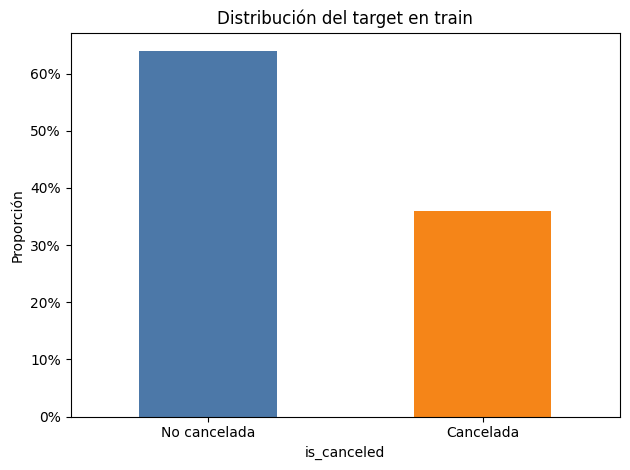

In [25]:
target_share = train_df[TARGET].value_counts(normalize=True).sort_index()
ax = target_share.plot.bar(color=["#4C78A8", "#F58518"], rot=0)
ax.set_xticklabels(["No cancelada", "Cancelada"])
ax.set_ylabel("Proporción")
ax.set_title("Distribución del target en train")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:.0%}"))
plt.tight_layout()
plt.show()

**Conclusión:** en el train temporal, el 36,1% de las reservas se canceló y el 63,9% no. La clase positiva es minoritaria, por lo que accuracy sola puede resultar engañosa; se priorizan Average Precision y el análisis conjunto de precisión/recall.

**Visualización 2:** tasa de cancelación por tipo de hotel, para comprobar si el contexto del hotel aporta señal predictiva.

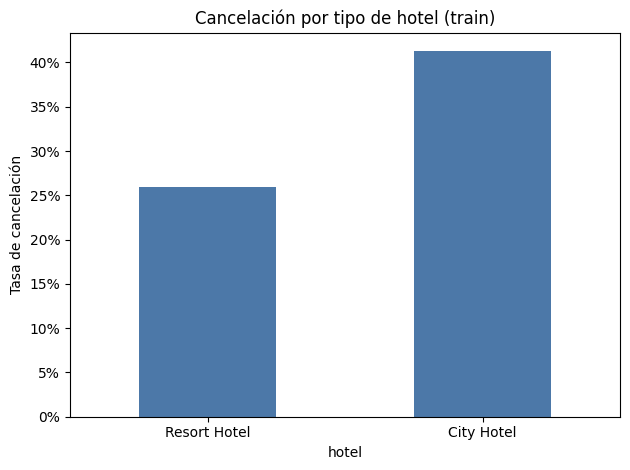

In [26]:
hotel_rates = train_df.groupby("hotel", observed=True)[TARGET].mean().sort_values()
ax = hotel_rates.plot.bar(color="#4C78A8", rot=0)
ax.set_ylabel("Tasa de cancelación")
ax.set_title("Cancelación por tipo de hotel (train)")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:.0%}"))
plt.tight_layout()
plt.show()

**Conclusión:** la tasa es aproximadamente 41,3% en City Hotel y 25,9% en Resort Hotel. La diferencia justifica conservar `hotel` y comprobar su aporte en validación; es una asociación, no evidencia causal.

**Visualización 3:** tasa de cancelación por mes de llegada, para explorar estacionalidad.

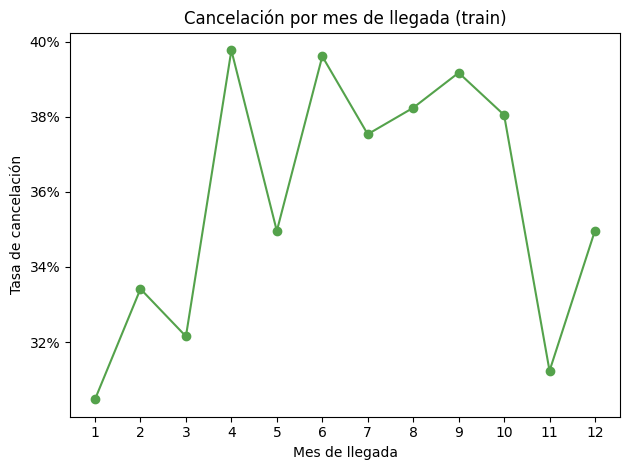

In [27]:
month_rates = train_df.groupby(train_df["arrival_date"].dt.month)[TARGET].mean()
ax = month_rates.plot(marker="o", color="#54A24B")
ax.set_xticks(range(1, 13))
ax.set_xlabel("Mes de llegada")
ax.set_ylabel("Tasa de cancelación")
ax.set_title("Cancelación por mes de llegada (train)")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:.0%}"))
plt.tight_layout()
plt.show()

**Conclusión:** las tasas varían por mes: en este train van aproximadamente de 30,5% (enero) a 39,8% (abril). Esto sugiere posible estacionalidad, que debe validarse temporalmente y no interpretarse como un efecto causal.

**Visualización 4:** tasa de cancelación por tramos de anticipación (`lead_time`), para evaluar una relación no lineal.

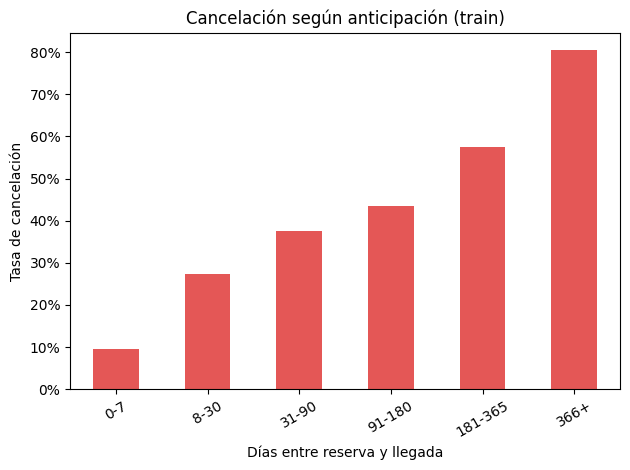

In [28]:
lead_bins = [-1, 7, 30, 90, 180, 365, np.inf]
lead_labels = ["0-7", "8-30", "31-90", "91-180", "181-365", "366+"]
lead_band = pd.cut(train_df["lead_time"], bins=lead_bins, labels=lead_labels)
lead_rates = train_df.groupby(lead_band, observed=True)[TARGET].mean()
ax = lead_rates.plot.bar(color="#E45756", rot=30)
ax.set_xlabel("Días entre reserva y llegada")
ax.set_ylabel("Tasa de cancelación")
ax.set_title("Cancelación según anticipación (train)")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:.0%}"))
plt.tight_layout()
plt.show()

**Conclusión:** la tasa aumenta desde 9,5% para anticipaciones de hasta 7 días hasta 80,6% para más de 365 días (este último tramo tiene 2.052 reservas). `lead_time` parece una señal importante; conviene permitir relaciones no lineales y revisar calibración por tramo.

**Visualización 5:** tasa de cancelación por tipo de depósito, para evaluar si las condiciones de pago se asocian con la cancelación.

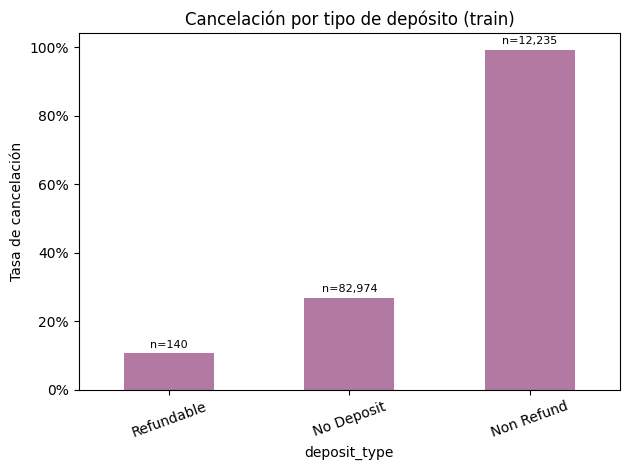

In [29]:
deposit_rates = train_df.groupby("deposit_type", observed=True)[TARGET].agg(["mean", "size"]).sort_values("mean")
ax = deposit_rates["mean"].plot.bar(color="#B279A2", rot=20)
ax.set_ylabel("Tasa de cancelación")
ax.set_title("Cancelación por tipo de depósito (train)")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:.0%}"))
for position, (rate, count) in enumerate(zip(deposit_rates["mean"], deposit_rates["size"])):
    ax.annotate(f"n={count:,}", (position, rate), xytext=(0, 4), textcoords="offset points", ha="center", fontsize=8)
plt.tight_layout()
plt.show()

**Conclusión:** las reservas Non Refund presentan una tasa cercana a 99,2%, frente a 26,8% en No Deposit y 10,7% en Refundable; el grupo Refundable es pequeño (140 casos). `deposit_type` es muy informativa, pero hay que verificar que se conozca al momento de predecir y no confundir asociación con causalidad.

**Visualización 6:** distribución de `adr` por resultado, ocultando puntos extremos y mostrando hasta el percentil 99 para que el centro sea legible.

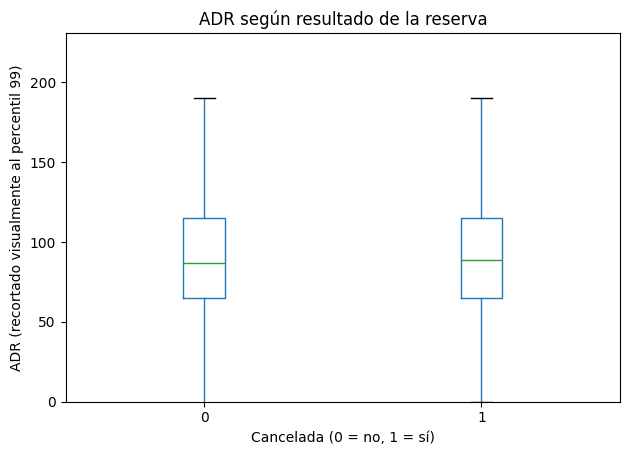

In [30]:
adr_plot = train_df[[TARGET, "adr"]].dropna().copy()
adr_upper = adr_plot["adr"].quantile(0.99)
adr_plot.boxplot(column="adr", by=TARGET, showfliers=False, grid=False)
plt.ylim(0, adr_upper)
plt.xlabel("Cancelada (0 = no, 1 = sí)")
plt.ylabel("ADR (recortado visualmente al percentil 99)")
plt.title("ADR según resultado de la reserva")
plt.suptitle("")
plt.tight_layout()
plt.show()

**Conclusión:** las medianas de ADR son parecidas (86,69 para no canceladas y 89,00 para canceladas), así que esta variable por sí sola separa poco en el centro de la distribución. El máximo llega a 5.400 y hay valores negativos; investigar esos extremos y validar la disponibilidad de `adr` al reservar antes de usarla.

## 4. Prevención de fuga de datos y estrategia de validación

### 4.1 Tabla de auditoría de variables (BORRADOR)

Para cada variable: si está disponible **al momento de reservar**, si puede ser un proxy del target y qué decisión se toma.
Este borrador sale del significado de cada columna, no de los datos: **hay que validarlo con el EDA** (por ejemplo,
comparando la distribución de cada variable dudosa entre reservas canceladas y no canceladas) y ajustarlo.

In [31]:
audit_rows = [
    # variable, disponible al reservar, riesgo de proxy, decisión, justificación
    ("hotel", "Sí", "Bajo", "Usar", "Tipo de hotel (resort o ciudad), conocido al reservar."),
    ("is_canceled", "-", "-", "Target", "Variable a predecir."),
    ("lead_time", "Sí", "Bajo", "Usar", "Días entre la reserva y la llegada; se conoce al reservar."),
    ("arrival_date_year", "Sí", "Bajo", "Transformar o descartar", "Con partición temporal el test cae en años/fechas no vistas; puede no generalizar."),
    ("arrival_date_month", "Sí", "Bajo", "Transformar", "Captura estacionalidad; codificar como número o de forma cíclica."),
    ("arrival_date_week_number", "Sí", "Bajo", "Evaluar", "Redundante con el mes; decidir en la selección de variables."),
    ("arrival_date_day_of_month", "Sí", "Bajo", "Evaluar", "Poco aporte esperado; medir en la ablation."),
    ("stays_in_weekend_nights", "Sí", "Bajo", "Usar", "Estadía planificada; verificar que no refleje cambios posteriores."),
    ("stays_in_week_nights", "Sí", "Bajo", "Usar", "Estadía planificada; verificar que no refleje cambios posteriores."),
    ("adults", "Sí", "Bajo", "Usar", "Composición de la reserva."),
    ("children", "Sí", "Bajo", "Usar", "Composición de la reserva; tiene pocos faltantes."),
    ("babies", "Sí", "Bajo", "Usar", "Composición de la reserva."),
    ("meal", "Sí", "Bajo", "Usar", "Régimen de comidas contratado."),
    ("country", "Sí", "Bajo", "Transformar", "Alta cardinalidad y faltantes: frecuencia o agrupación de categorías raras."),
    ("market_segment", "Sí", "Bajo", "Usar", "Segmento de mercado; revisar categorías raras o 'Undefined'."),
    ("distribution_channel", "Sí", "Bajo", "Usar", "Canal de distribución; revisar categorías raras o 'Undefined'."),
    ("is_repeated_guest", "Sí", "Bajo", "Usar", "Dato del huésped previo a la reserva."),
    ("previous_cancellations", "Sí", "Bajo", "Usar", "Historial del cliente anterior a esta reserva."),
    ("previous_bookings_not_canceled", "Sí", "Bajo", "Usar", "Historial del cliente anterior a esta reserva."),
    ("reserved_room_type", "Sí", "Bajo", "Usar", "Tipo de habitación reservada."),
    ("assigned_room_type", "Dudosa", "Alto", "Descartar (a validar)", "Se asigna cerca de la estadía y puede diferir de la reservada; candidata a fuga. Validar con el EDA."),
    ("booking_changes", "No", "Alto", "Descartar (a validar)", "Cuenta cambios posteriores a la creación de la reserva; no se conoce al reservar."),
    ("deposit_type", "Sí", "Medio", "Evaluar", "Se conoce al reservar, pero revisar su relación con el target por posible proxy."),
    ("agent", "Sí", "Bajo", "Transformar", "Alta cardinalidad y faltantes: frecuencia, agrupación e indicador de faltante."),
    ("company", "Sí", "Bajo", "Transformar", "Muchos faltantes: indicador de presencia, agrupación."),
    ("days_in_waiting_list", "Dudosa", "Medio", "Evaluar", "Se conoce al confirmarse la reserva; ver si es válida al momento de predecir."),
    ("customer_type", "Sí", "Bajo", "Usar", "Tipo de cliente (contrato, grupo, transient)."),
    ("adr", "Dudosa", "Medio", "Evaluar", "Tarifa diaria promedio; verificar cómo se calculó y si incluye cargos posteriores."),
    ("required_car_parking_spaces", "Dudosa", "Medio", "Evaluar", "Verificar cuándo se registra y si se relaciona con el target."),
    ("total_of_special_requests", "Dudosa", "Medio", "Evaluar", "Verificar cuándo se registran los pedidos especiales."),
    ("reservation_status", "No", "Muy alto", "Descartar", "Fuga directa: informa si la reserva fue cancelada, hizo check-out o no se presentó. Solo para el experimento de fuga."),
    ("reservation_status_date", "No", "Muy alto", "Descartar", "Fecha del último estado de la reserva; fuga. Solo para el experimento de fuga."),
]

audit = pd.DataFrame(audit_rows, columns=[
    "variable", "disponible_al_reservar", "riesgo_proxy", "decision", "justificacion"])

# Control de cobertura: toda columna del dataset debe estar auditada.
cols_dataset = set(train_df.columns) - {"arrival_date"}  # arrival_date es derivada
sin_auditar = cols_dataset - set(audit["variable"])
sobran = set(audit["variable"]) - cols_dataset
print("Sin auditar:", sin_auditar or "ninguna")
print("En la tabla pero no en el dataset:", sobran or "ninguna")

audit

Sin auditar: ninguna
En la tabla pero no en el dataset: ninguna


,variable,disponible_al_reservar,riesgo_proxy,decision,justificacion
0,hotel,Sí,Bajo,Usar,"Tipo de hotel (resort o ciudad), conocido al r..."
1,is_canceled,-,-,Target,Variable a predecir.
2,lead_time,Sí,Bajo,Usar,Días entre la reserva y la llegada; se conoce ...
3,arrival_date_year,Sí,Bajo,Transformar o descartar,Con partición temporal el test cae en años/fec...
4,arrival_date_month,Sí,Bajo,Transformar,Captura estacionalidad; codificar como número ...
5,arrival_date_week_number,Sí,Bajo,Evaluar,Redundante con el mes; decidir en la selección...
6,arrival_date_day_of_month,Sí,Bajo,Evaluar,Poco aporte esperado; medir en la ablation.
7,stays_in_weekend_nights,Sí,Bajo,Usar,Estadía planificada; verificar que no refleje ...
8,stays_in_week_nights,Sí,Bajo,Usar,Estadía planificada; verificar que no refleje ...
9,adults,Sí,Bajo,Usar,Composición de la reserva.


In [32]:
# Columnas que se usan SOLO en el experimento de fuga (sección 6.4), nunca en el modelo real.
LEAK_COLS = ["reservation_status", "reservation_status_date"]

### 4.2 Preprocesamiento sin fuga
_(Imputación, escalado y codificación dentro de un `Pipeline` / `ColumnTransformer`, ajustados solo con datos de entrenamiento, también dentro de la validación cruzada. Cualquier transformación que aprenda de los datos —frecuencias, target encoding, medias— va dentro del Pipeline.)_

## 5. Feature engineering

Mínimo 8 variables nuevas, cada una con su hipótesis. **Ideas candidatas** (validar cuáles se usan):

| Variable | Hipótesis de por qué podría ayudar |
|---|---|
| `total_nights` | Las estadías largas podrían tener distinta probabilidad de cancelación. |
| `total_guests` | El tamaño del grupo puede relacionarse con la dificultad de organizar el viaje. |
| `has_children` | Las reservas con niños podrían ser más o menos propensas a cancelarse. |
| `arrival_month` (cíclica) | Estacionalidad de las cancelaciones. |
| `arrival_dow` / llegada en fin de semana | El día de llegada puede cambiar el comportamiento. |
| `lead_time` por tramos | Reservas hechas con mucha anticipación suelen cancelarse más. |
| frecuencia de `country` | Reemplaza una variable de alta cardinalidad por su frecuencia. |
| frecuencia de `agent` | Idem para agencias. |
| `prev_cancel_ratio` | Proporción de cancelaciones previas del cliente. |
| `adr` por persona | Precio relativo al tamaño de la reserva. |

Además: tratamiento justificado de categóricas, **ablation** por familia de variables, y al menos un método de selección de variables.

In [33]:
# Ejemplos de variables SIN estado (no aprenden de los datos, se pueden calcular fuera del Pipeline).
def add_stateless_features(d):
    d = d.copy()
    d["total_nights"] = d["stays_in_weekend_nights"] + d["stays_in_week_nights"]
    d["total_guests"] = d["adults"] + d["children"].fillna(0) + d["babies"]
    d["has_children"] = ((d["children"].fillna(0) + d["babies"]) > 0).astype(int)
    d["arrival_month"] = d["arrival_date"].dt.month
    d["arrival_dow"] = d["arrival_date"].dt.dayofweek
    d["arrival_is_weekend"] = d["arrival_dow"].isin([5, 6]).astype(int)
    d["arrival_month_sin"] = np.sin(2 * np.pi * d["arrival_month"] / 12)
    d["arrival_month_cos"] = np.cos(2 * np.pi * d["arrival_month"] / 12)
    d["lead_time_band"] = pd.cut(
        d["lead_time"],
        bins=[-1, 7, 30, 90, 180, 365, np.inf],
        labels=["0-7", "8-30", "31-90", "91-180", "181-365", "366+"],
    ).astype("object")
    prior_bookings = d["previous_cancellations"] + d["previous_bookings_not_canceled"]
    d["prev_cancel_ratio"] = d["previous_cancellations"].div(prior_bookings.where(prior_bookings > 0)).fillna(0)
    d["adr_per_guest"] = d["adr"].div(d["total_guests"].where(d["total_guests"] > 0))
    return d

train_df = add_stateless_features(train_df)

print("Variables derivadas:", ["total_nights", "total_guests", "has_children", "arrival_month", "arrival_dow", "arrival_is_weekend", "arrival_month_sin", "arrival_month_cos", "lead_time_band", "prev_cancel_ratio", "adr_per_guest"])
print("Dimensiones de train con variables derivadas:", train_df.shape)

Variables derivadas: ['total_nights', 'total_guests', 'has_children', 'arrival_month', 'arrival_dow', 'arrival_is_weekend', 'arrival_month_sin', 'arrival_month_cos', 'lead_time_band', 'prev_cancel_ratio', 'adr_per_guest']
Dimensiones de train con variables derivadas: (95349, 44)


## 6. Modelado

### 6.1 Baselines
- [ ] Modelo trivial (por ejemplo `DummyClassifier`)
- [ ] Regresión logística

### 6.2 Comparación de algoritmos (al menos 4 familias)
- [ ] Lineal
- [ ] Árboles / Random Forest
- [ ] Boosting (XGBoost o LightGBM)
- [ ] Uno más a elección

### 6.3 Validación y ajuste
- [ ] Validación cruzada de al menos 5 folds (dentro del train)
- [ ] Ajuste de hiperparámetros sobre validación, **nunca sobre el test**
- [ ] Manejo del desbalance (si corresponde)
- [ ] Calibración de probabilidades
- [ ] Elección del umbral según el costo de los errores

### 6.4 Experimento de fuga
- [ ] Introducir a propósito una fuga (por ejemplo `reservation_status`, columnas de `LEAK_COLS`) y mostrar cuánto se infla la métrica
- [ ] Comparar contra el modelo honesto

In [34]:
# TODO: baselines, modelos, validación cruzada y experimento de fuga

## 7. Evaluación final e interpretación

El mejor modelo se evalúa **una sola vez** sobre el test. Ejecutar la celda de carga solo cuando el modelo final ya esté decidido.

- [ ] Matriz de confusión, precision, recall, F1, ROC-AUC y curva precision-recall
- [ ] Intervalos de confianza (por ejemplo bootstrap)
- [ ] Análisis de errores
- [ ] Interpretabilidad: permutation importance y al menos una técnica adicional (SHAP o dependencia parcial)
- [ ] Comparación contra el baseline y contra el modelo "inflado" del experimento de fuga

In [35]:
# Ejecutar UNA sola vez, con el modelo final ya decidido.
test_df = pd.read_csv("test_holdout.csv", parse_dates=["arrival_date"])
test_df = add_stateless_features(test_df)
print("Test:", test_df.shape)

Test: (24041, 44)


## 8. Responsabilidad, riesgos y puesta en producción

- [ ] ¿Puede usarse el modelo tal cual? ¿Bajo qué condiciones?
- [ ] Riesgos de los errores y posibles sesgos o diferencias de desempeño entre subgrupos (por ejemplo por hotel, país, segmento)
- [ ] Qué monitorear en producción (cambios en los datos, caída del desempeño) y cuándo reentrenar
- [ ] Modelo empaquetado: pipeline completo guardado (por ejemplo `joblib.dump(pipeline, "modelo.joblib")`) y un script `predict.py` que lo cargue y prediga sobre un ejemplo nuevo

## 9. Uso de IA

Registrar desde ya, para el informe: en qué tareas se usó IA y **al menos una corrección** que se hizo sobre lo que generó.

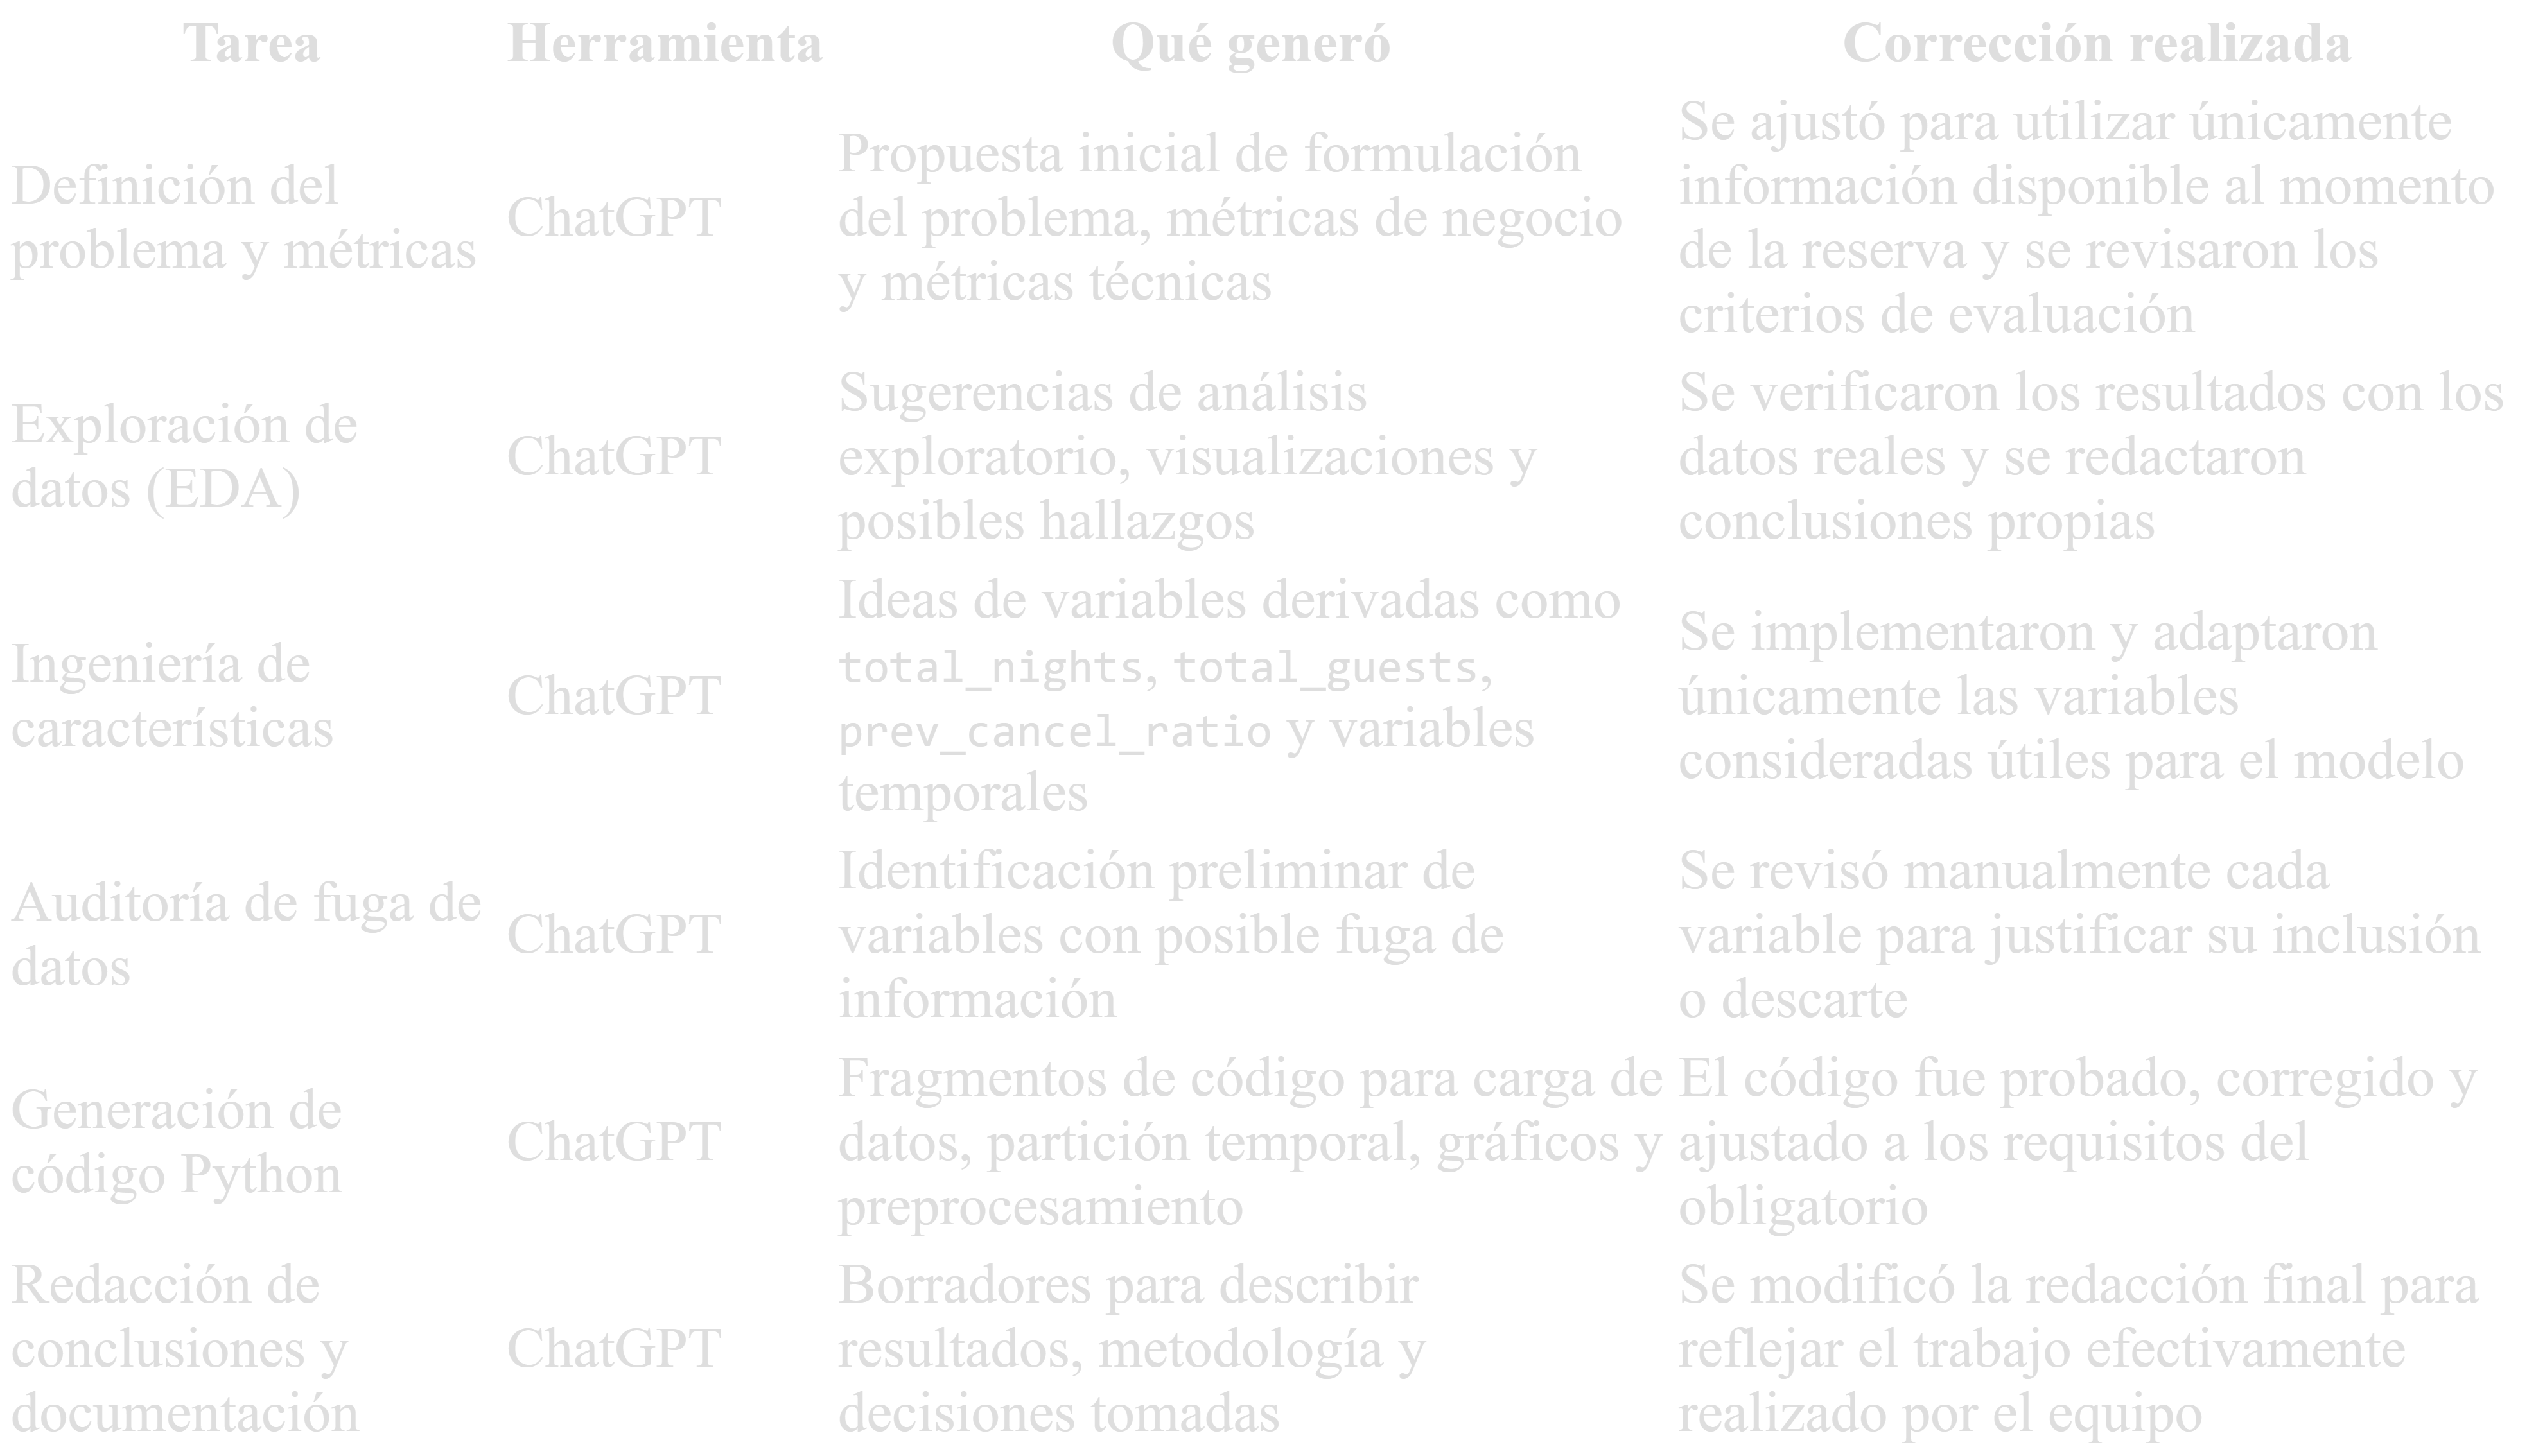
A partir del análisis realizado sobre el dataset Hotel Booking Demand, se comprobó que el problema de predicción de cancelaciones es viable desde el punto de vista de aprendizaje automático. La variable objetivo presenta un desbalance moderado (36,1% de cancelaciones en entrenamiento), por lo que se descartó utilizar accuracy como métrica principal y se propuso emplear Average Precision junto con métricas complementarias como precisión, recall, F1 y ROC-AUC.

La partición temporal permitió simular un escenario más cercano al uso en producción, entrenando con reservas pasadas y evaluando sobre reservas futuras. Esta decisión reduce el riesgo de sobreestimar el desempeño del modelo respecto a una partición aleatoria convencional.

Durante el EDA se identificaron variables con una fuerte asociación con la cancelación, especialmente lead_time, deposit_type y hotel, además de ciertos patrones estacionales relacionados con la fecha de llegada. También se detectaron variables potencialmente problemáticas desde el punto de vista de la fuga de información, como reservation_status y reservation_status_date, que fueron marcadas para ser excluidas del entrenamiento.

Se generaron nuevas variables derivadas con el objetivo de capturar información de negocio de forma más representativa, incluyendo duración total de la estadía, número total de huéspedes, presencia de niños, características temporales y métricas basadas en el historial previo del cliente. Estas variables buscan facilitar que los modelos identifiquen patrones relevantes sin incorporar información futura.

Finalmente, se definió una estrategia de modelado basada en pipelines y validación temporal, con el objetivo de garantizar reproducibilidad y evitar fuga de datos durante el preprocesamiento. Los modelos a evaluar incluirán enfoques lineales y basados en árboles, comparándose contra un baseline simple para determinar si aportan valor real al problema de negocio.

Como trabajo futuro, resta completar el entrenamiento de los modelos, realizar la selección de hiperparámetros, evaluar el desempeño en el conjunto de prueba reservado y analizar la interpretabilidad de las predicciones antes de considerar una posible implementación en producción.